In [69]:
import torch
from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.acquisition.multi_objective.monte_carlo import qExpectedHypervolumeImprovement
from botorch.optim import optimize_acqf
from botorch.utils.multi_objective.box_decompositions.non_dominated import FastNondominatedPartitioning
from botorch.utils.multi_objective.pareto import is_non_dominated
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.fit import fit_gpytorch_mll

import matplotlib.pyplot as plt

In [70]:
def f_objective(x: torch.Tensor) -> torch.Tensor:
    """
    Blackbox 2D objective function
    """
    f1 = torch.sin(3.0 * torch.pi * x) - 0.4 * x
    f2 = torch.cos(2.0 * torch.pi * (x - 0.5)) + 0.3 * x
    return torch.cat([f1, f2], dim=-1)

In [71]:
tkwargs = {"dtype": torch.double, "device": torch.device("cpu")}
torch.manual_seed(42)

bounds = torch.tensor([[0.0], [10.0]], dtype=torch.double)
ref_point = torch.tensor([0.0, 0.0], dtype=torch.double)

n_init = 5
train_x = bounds[0] + (bounds[1] - bounds[0]) * torch.rand(n_init, 1, dtype=torch.double)
train_y = f_objective(train_x)

In [72]:
RUNS = 10

for i in range(RUNS):
    model = SingleTaskGP(
        train_x,
        train_y,
        input_transform=Normalize(d=1),
        outcome_transform=Standardize(m=2)
    )
    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)

    partitioning = FastNondominatedPartitioning(ref_point=ref_point, Y=train_y)

    acq_func = qExpectedHypervolumeImprovement(
        model=model,
        ref_point=ref_point,
        partitioning=partitioning
    )

    candidates, _ = optimize_acqf(
        acq_function=acq_func,
        bounds=bounds,
        q=1,
        num_restarts=5,
        raw_samples=100
    )

    new_y = f_objective(candidates)
    train_x = torch.cat([train_x, candidates])
    train_y = torch.cat([train_y, new_y])

/Users/colin/Library/CloudStorage/OneDrive-UniversityofCambridge/II/Dissertation/MOBO_cloud/.venv/lib/python3.13/site-packages/botorch/acquisition/multi_objective/monte_carlo.py:110: NumericsWarning: qExpectedHypervolumeImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 qExpectedHypervolumeImprovement 	 --> 	 qLogExpectedHypervolumeImprovement 

instead, which fixes the issues and has the same API. See https://arxiv.org/abs/2310.20708 for details.
  legacy_ei_numerics_warning(legacy_name=type(self).__name__)
/Users/colin/Library/CloudStorage/OneDrive-UniversityofCambridge/II/Dissertation/MOBO_cloud/.venv/lib/python3.13/site-packages/botorch/acquisition/multi_objective/monte_carlo.py:110: NumericsWarning: qExpectedHypervolumeImprovement has known numerical issues that lead to suboptimal optimization performance. It is strongly recommended to simply replace

	 qExpectedHypervolumeImprovement 	 --> 	 qLo


--- MOBO Finished ---
Total Evaluations: 15
Found 9 Pareto-optimal points:
  x = 10.0000 --> f1 = -4.000, f2 = 2.000
  x = 5.2617 --> f1 = -2.730, f2 = 1.652
  x = 0.5258 --> f1 = -1.181, f2 = 1.145
  x = 0.4374 --> f1 = -1.006, f2 = 1.055
  x = 0.5815 --> f1 = -0.952, f2 = 1.046
  x = 0.6291 --> f1 = -0.598, f2 = 0.877
  x = 0.3177 --> f1 = 0.020, f2 = 0.508
  x = 0.2995 --> f1 = 0.194, f2 = 0.396
  x = 0.2134 --> f1 = 0.819, f2 = -0.164


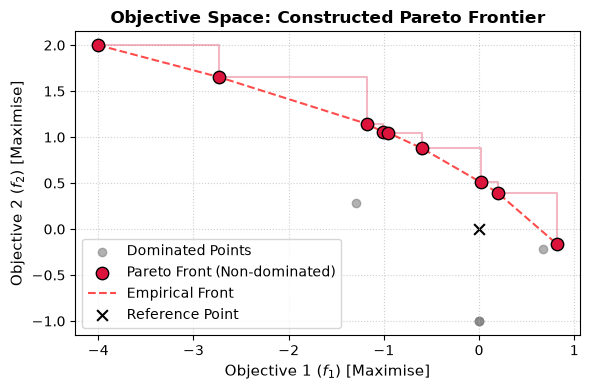

In [73]:
pareto_mask = is_non_dominated(train_y)

pareto_x = train_x[pareto_mask]
pareto_y = train_y[pareto_mask]
dominated_x = train_x[~pareto_mask]
dominated_y = train_y[~pareto_mask]

# Sort Pareto points by first objective to plot an ordered frontier
sorted_indices = torch.argsort(pareto_y[:, 0])
pareto_x_sorted = pareto_x[sorted_indices]
pareto_y_sorted = pareto_y[sorted_indices]

print("\n--- MOBO Finished ---")
print(f"Total Evaluations: {len(train_x)}")
print(f"Found {len(pareto_y_sorted)} Pareto-optimal points:")
for i in range(len(pareto_y_sorted)):
    print(
        f"  x = {pareto_x_sorted[i, 0].item():.4f} --> "
        f"f1 = {pareto_y_sorted[i, 0].item():.3f}, f2 = {pareto_y_sorted[i, 1].item():.3f}"
    )

# Visualizing trade-off & parameter Space
fig, ax = plt.subplots(1, 1, figsize=(6, 4))

# Objective space showing Pareto frontier
ax.scatter(
    dominated_y[:, 0].numpy(),
    dominated_y[:, 1].numpy(),
    color="gray",
    alpha=0.6,
    label="Dominated Points",
)
ax.scatter(
    pareto_y_sorted[:, 0].numpy(),
    pareto_y_sorted[:, 1].numpy(),
    color="crimson",
    s=80,
    edgecolors="k",
    zorder=5,
    label="Pareto Front (Non-dominated)",
)
ax.plot(
    pareto_y_sorted[:, 0].numpy(),
    pareto_y_sorted[:, 1].numpy(),
    "r--",
    alpha=0.7,
    label="Empirical Front",
)
ax.step(
    pareto_y_sorted[:, 0].numpy(),
    pareto_y_sorted[:, 1].numpy(),
    where="post",
    color="crimson",
    alpha=0.3,
)
ax.scatter(
    [ref_point[0].item()],
    [ref_point[1].item()],
    color="black",
    marker="x",
    s=60,
    label="Reference Point",
)

ax.set_title("Objective Space: Constructed Pareto Frontier", fontweight="bold")
ax.set_xlabel("Objective 1 ($f_1$) [Maximise]", fontsize=11)
ax.set_ylabel("Objective 2 ($f_2$) [Maximise]", fontsize=11)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()